# A Shared Active Subspace for Hydrogen/Air Ignition Delays and Flame Speeds: 33 Uncertain Rate Constants

__Weiqi Ji__, Center for Combustion Energy, Tsinghua University, Beijing, China

__Jiaxing Wang__, Center for Combustion Energy, and Department of Thermal Engineering, Tsinghua University, Beijing, China

__Olivier Zahm__, Department of Aeronautics and Astronautics, Massachusetts Institute of Technology, Cambridge, MA, USA

__Youssef M. Marzouk__, Department of Aeronautics and Astronautics, Massachusetts Institute of Technology, Cambridge, MA, USA

__Bin Yang__, Center for Combustion Energy, and Department of Thermal Engineering, Tsinghua University, Beijing, China

__Zhuyin Ren__, Center for Combustion Energy, and School of Aerospace Engineering, Tsinghua University, Beijing, China

__Chung K. Law__, Center for Combustion Energy, Tsinghua University, Beijing, China, and Department of Mechanical and Aerospace Engineering, Princeton University, Princeton, NJ, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, scipy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1.0 or later) and reads the shipped data files. In the repository's terms this is a **stored-data** set: the data were computed with [Cantera](https://cantera.org) 3.2.0, an outside code, by the included `generate_data.py` and `h2_konnov_driver.py`; `DATA.md` has the full provenance. Cantera, and the mechanism file rebuilt by `build_mechanism.py` from the supplementary files of Konnov (2008), are needed only to regenerate the data.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
import active_subspaces as ac
import h2_konnov_driver as hd   # reaction list, uncertainty factors, conditions (numpy only); solving needs Cantera

SEED = 2018                      # the only seed in this notebook (bootstrap and Algorithm 2.2 draws)
t_start = time.perf_counter()
NI, NO = hd.N_IDT, hd.N_OUT      # 16 ignition outputs, 21 outputs in all
short = ([f'IDT {p:.3g} atm {t:.0f} K' for p, t in hd.IDT_CONDITIONS]
         + [f'SL {p:g} atm' for p in hd.SL_P])

### Summary

Ji et al. [[1]](https://doi.org/10.1016/j.combustflame.2017.11.021) estimate active subspaces of combustion outputs with respect to the uncertain rate constants of a kinetic mechanism, and combine the first eigenvectors of several outputs into one *shared* direction $v$ that reproduces each output's distribution. For hydrogen they show one output, the ignition delay at 1.59 bar and 1000 K with Konnov's 33-reaction mechanism (Fig. 1); their shared-subspace demonstration uses methane. We rebuild the hydrogen case in Cantera with the same mechanism, uncertainty factors and input distribution, compute 16 ignition delays and 5 flame speeds with gradients at 350 samples, and apply the paper's shared-subspace construction to hydrogen: every output has a one-dimensional active subspace ($\lambda_1/\lambda_2$ between 51 and 1124), the 20 first eigenvectors are far from parallel (cosines down to 0.095), and one shared direction approximates all 21 outputs, including the held-out Fig. 1 condition, about as well as each output's own eigenvector does: the ignition-delay distributions are matched closely, while the flame-speed means come out 0.017–0.024 m/s high with either direction.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend and a low-degree function of $\mathbf y$ can stand in for $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

**Inputs** (paper Eqs. 1–2, p. 148). Each of the $d = 33$ reactions of the Konnov (2008) H$_2$/O$_2$ mechanism [[2]](https://doi.org/10.1016/j.combustflame.2007.10.024) (10 species; paper Table 1, p. 150) has a rate constant $k_j$ with nominal value $k_{j0}$ and a temperature-independent uncertainty factor $\mathrm{UF}_j$, and

$$
\ln k_j \sim \mathcal N\!\left(\ln k_{j0},\ \left(\tfrac13\ln \mathrm{UF}_j\right)^2\right),\quad \text{truncated to } [k_{j0}/\mathrm{UF}_j,\ k_{j0}\,\mathrm{UF}_j],\qquad
x_j = \frac{\ln(k_j/k_{j0})}{\tfrac13\ln \mathrm{UF}_j}.
$$

So each normalized input $x_j$ is a standard normal truncated to $[-3, 3]$. The perturbation multiplies the whole rate of reaction $j$ (falloff and third-body rates included; reverse rates follow through the equilibrium constant). The paper takes the factors from Konnov's paper and does not print them; we read them from Konnov's Table 1 (pp. 509–510). Konnov lists some reactions as several entries (1a–1d, 4a–4b, 5a–5d, 6a–6b, 17a–17b) and three as sums of two expressions (16, 17a, 21); in the mechanism file these are 33 separate reactions, which matches the paper's count. Each takes the UF printed on its own line; where Konnov prints a second factor for a low-pressure limit or for collision efficiencies (5c: 1.3; 1a: 5), we use the first, as the factors are per rate constant. Reaction indices below are positions in the mechanism file, which is the numbering of the paper's Fig. 1c (R16 = H + O$_2$ = OH + O, R9 = H + O$_2$ (+M) = HO$_2$ (+M)); we write them $x_1,\dots,x_{33}$. The table is printed from `h2_konnov_driver.py`.

**Outputs** (paper Table 2 and Sec. 3.2, pp. 151–152). For a stoichiometric H$_2$/air mixture (H$_2$ : O$_2$ : N$_2$ = 2 : 1 : 3.76 by moles; the paper says only "hydrogen/air"):

- the **ignition delay** $\tau$ of an adiabatic constant-volume reactor, $\frac{dY_k}{dt} = \frac{W_k\dot\omega_k}{\rho}$, $\frac{dT}{dt} = -\frac{1}{\rho c_v}\sum_k u_k\dot\omega_k$, at 1.59 bar and 1000 K (Fig. 1) and on the paper's grid $P$ = 1, 2, 5, 10, 20 atm $\times$ $T_0$ = 1000, 1400, 1800 K (16 conditions). The paper does not define $\tau$ for these runs; we use the first time $T$ reaches $T_0 + 400$ K. The paper analyses $\log_{10}\tau$ (p. 151), and so do we;
- the **laminar flame speed** $S_L$ of a freely propagating, adiabatic, one-dimensional premixed flame (mixture-averaged transport) at $T_u$ = 300 K and $P$ = 1, 2, 5, 10, 20 atm (5 conditions), in m/s.

The paper's shared-subspace example (Sec. 3.2) uses exactly this grid of 15 ignition and 5 flame conditions ($m$ = 20 outputs), but for methane; here it is applied to hydrogen, with the Fig. 1 condition held out as a test.

**Gradients.** Forward differences $k_j \to (1 + \delta)k_j$ with $\delta = 10^{-3}$ for both outputs (paper Eq. 20), converted to $x$ by $\partial f/\partial x_j = \tfrac13\ln\mathrm{UF}_j\,\partial f/\partial\ln k_j$ (Eq. 19). The paper used an adjoint for $S_L$ (p. 150); we use finite differences on the converged flame's grid. Cantera's built-in flame-speed sensitivity is the derivative with respect to the rate multiplier $m_j = k_j/k_{j0}$, $\partial\ln S_L/\partial m_j$; multiplied by the sample's $m_j$ (chain rule) it gives $\partial\ln S_L/\partial\ln k_j$, and then it agrees with an adjoint that perturbs $m_j$ in log coordinates to about $4\times10^{-11}$ and with our finite differences to about $2\times10^{-3}$ (`DATA.md`, Accuracy).

In [2]:
print(f"{'x_j':4s} {'Konnov':9s} {'reaction':24s} {'UF':>4s} {'sigma_j':>8s}  k_j/k_j0 range")
for j in range(hd.M_IN):
    print(f"x{j + 1:<3d} {hd.KONNOV_NO[j]:9s} {hd.EQUATIONS[j]:24s} {hd.UF[j]:4.1f} {hd.SIGMA[j]:8.4f}"
          f"  [{1 / hd.UF[j]:.3f}, {hd.UF[j]:.1f}]")
print('ignition conditions (P atm, T0 K):', [(round(p, 4), t) for p, t in hd.IDT_CONDITIONS])
print('flame pressures (atm), T_u = 300 K:', hd.SL_P)

x_j  Konnov    reaction                   UF  sigma_j  k_j/k_j0 range
x1   1a        H+H+M=H2+M                2.0   0.2310  [0.500, 2.0]
x2   1b        H+H+H2=H2+H2              2.5   0.3054  [0.400, 2.5]
x3   1c        H+H+N2=H2+N2              3.2   0.3877  [0.312, 3.2]
x4   1d        H+H+H=H2+H                3.2   0.3877  [0.312, 3.2]
x5   2         O+O+M=O2+M                2.0   0.2310  [0.500, 2.0]
x6   3         O+H+M=OH+M                3.0   0.3662  [0.333, 3.0]
x7   4a        H2O+M=H+OH+M              2.0   0.2310  [0.500, 2.0]
x8   4b        H2O+H2O=H+OH+H2O          2.0   0.2310  [0.500, 2.0]
x9   5a        H+O2(+M)=HO2(+M)          1.2   0.0608  [0.833, 1.2]
x10  5b        H+O2(+Ar)=HO2(+Ar)        1.2   0.0608  [0.833, 1.2]
x11  5c        H+O2(+O2)=HO2(+O2)        1.2   0.0608  [0.833, 1.2]
x12  5d        H+O2(+H2O)=HO2(+H2O)      1.4   0.1122  [0.714, 1.4]
x13  6a        OH+OH(+M)=H2O2(+M)        2.5   0.3054  [0.400, 2.5]
x14  6b        OH+OH(+H2O)=H2O2(+H2O)    2.5  

### Load the data

`inputs.csv` holds $\ln(k_j/k_{j0})$ for 350 samples, `outputs.csv` the 21 outputs ($\tau$ in s, $S_L$ in m/s), `gradients.csv` their derivatives with respect to $\ln k_j$, and `mc_*.csv` 1000 further samples without gradients. `directions.csv` and `line_runs.csv` hold the model evaluated along the directions found below; they are used in the last section.

In [3]:
L = np.loadtxt('inputs.csv', delimiter=',')            # ln(k_j/k_j0), 350 x 33
F = np.loadtxt('outputs.csv', delimiter=',')           # tau (s) x 16, S_L (m/s) x 5
G = np.loadtxt('gradients.csv', delimiter=',')         # df_i/dln k_j, 350 x (21*33)
Lmc = np.loadtxt('mc_inputs.csv', delimiter=',')       # 1000 x 33
Fmc = np.loadtxt('mc_outputs.csv', delimiter=',')      # 1000 x 21
DIR = np.loadtxt('directions.csv', delimiter=',')      # u_1..u_21, then v (22 x 33)
LR = np.loadtxt('line_runs.csv', delimiter=',')        # xi, f_i(xi v) x 21, f_i(xi u_i) x 21
G = G.reshape(len(L), NO, hd.M_IN)
for name, A in [('inputs', L), ('outputs', F), ('gradients', G), ('mc_inputs', Lmc), ('mc_outputs', Fmc),
                ('directions', DIR), ('line_runs', LR)]:
    print(f'{name:11s} {A.shape}')
# analysed QoIs: log10(tau) (paper p. 151) and S_L in m/s; gradients w.r.t. ln k_j
Q = F.copy(); Q[:, :NI] = np.log10(F[:, :NI])
Qmc = Fmc.copy(); Qmc[:, :NI] = np.log10(Fmc[:, :NI])
dQ = G.copy(); dQ[:, :NI, :] = G[:, :NI, :] / (F[:, :NI, None] * np.log(10.0))
X, Xmc = L / hd.SIGMA, Lmc / hd.SIGMA                  # normalized inputs, Eq. (2)

inputs      (350, 33)
outputs     (350, 21)
gradients   (350, 21, 33)
mc_inputs   (1000, 33)
mc_outputs  (1000, 21)
directions  (22, 33)
line_runs   (49, 43)


In [4]:
for nm, Z in [('gradient set', X), ('MC set', Xmc)]:
    kurt = np.mean(Z**4, 0) / np.mean(Z**2, 0)**2
    print(f'{nm}: x in [{Z.min():.3f}, {Z.max():.3f}], column means {Z.mean(0).min():+.3f} to '
          f'{Z.mean(0).max():+.3f}, sds {Z.std(0).min():.3f} to {Z.std(0).max():.3f}, kurtosis '
          f'{kurt.min():.2f} to {kurt.max():.2f}; duplicate rows {len(Z) - len(np.unique(Z, axis=0))}')
print(f'all outputs finite and positive: {np.all(np.isfinite(F)) and np.all(F > 0)}, '
      f'{np.all(np.isfinite(Fmc)) and np.all(Fmc > 0)}; gradients finite: {np.all(np.isfinite(G))}')
cos = []
for i in range(NO):
    b = np.linalg.lstsq(np.column_stack([np.ones(len(X)), X]), Q[:, i], rcond=None)[0][1:]
    g = (dQ[:, i, :] * hd.SIGMA).mean(0)
    cos.append(b @ g / np.linalg.norm(b) / np.linalg.norm(g))
rel = np.abs(G * hd.SIGMA).max(0) / np.abs(G * hd.SIGMA).max((0, 2))[:, None]   # per output, per input
print(f'largest |df/dx10| (H+O2(+Ar), no argon in the mixture) relative to the largest gradient component: '
      f'{rel[:, 9].max():.1e}; next smallest input: {np.sort(rel.max(0))[1]:.1e}')
print(f'OLS slope on x vs mean normalized gradient, cosine over the 21 outputs: {min(cos):.4f} to {max(cos):.4f}')
for i in range(NO):
    print(f'  {short[i]:20s} median {np.median(F[:, i]):.4e}  range [{F[:, i].min():.4e}, {F[:, i].max():.4e}]'
          f' {"s" if i < NI else "m/s"}')

gradient set: x in [-2.990, 2.979], column means -0.125 to +0.149, sds 0.874 to 1.063, kurtosis 2.38 to 3.20; duplicate rows 0
MC set: x in [-2.998, 2.995], column means -0.064 to +0.060, sds 0.933 to 1.025, kurtosis 2.66 to 3.09; duplicate rows 0
all outputs finite and positive: True, True; gradients finite: True
largest |df/dx10| (H+O2(+Ar), no argon in the mixture) relative to the largest gradient component: 8.2e-07; next smallest input: 3.4e-03
OLS slope on x vs mean normalized gradient, cosine over the 21 outputs: 0.9904 to 0.9999
  IDT 1.57 atm 1000 K  median 1.4117e-04  range [8.0335e-05, 3.4177e-04] s
  IDT 1 atm 1000 K     median 1.6387e-04  range [1.0947e-04, 2.6301e-04] s
  IDT 1 atm 1400 K     median 1.8009e-05  range [1.4183e-05, 2.3664e-05] s
  IDT 1 atm 1800 K     median 8.7133e-06  range [7.1939e-06, 1.0781e-05] s
  IDT 2 atm 1000 K     median 1.5464e-04  range [7.2114e-05, 1.9640e-03] s
  IDT 2 atm 1400 K     median 8.5892e-06  range [6.6801e-06, 1.1356e-05] s
  IDT 2 

The inputs behave as a truncated standard normal should: all within $[-3, 3]$, sample means within 0.15 of 0 and standard deviations between 0.874 and 1.063 in the gradient set (0.933 to 1.025 in the Monte Carlo set), with no duplicate rows. Every output is finite and positive. The least-squares slope of each output on $\mathbf x$ points the same way as its mean gradient (cosines at least 0.990), which confirms the gradient coordinates. One input has no physical effect: $x_{10}$, H + O$_2$ (+Ar), because the mixture contains no argon; its finite-difference gradients are below $10^{-6}$ of the largest component (solver noise). The ignition delays at 1000 K jump by more than an order of magnitude between 2 and 5 atm, where the mixture crosses the second explosion limit and ignition runs through HO$_2$ and H$_2$O$_2$.

### Estimate the subspaces

The gradients are available, so we use the gradient estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i\nabla f_i\nabla f_i^T$ with $M = 350$, for each of the 21 outputs. The paper's Algorithm 2.1 draws $M = \alpha\beta\log d$ samples with $\alpha = \beta = 10$ (p. 148, p. 151); for $d = 33$ that is 350, the size used here. The inputs are independent Gaussians in $\ln k$ with standard deviations $\sigma_j = \frac13\ln\mathrm{UF}_j$, so `ac.Gaussian(0, sigma**2)` scales each input by its own $\sigma_j$, which is the paper's normalization (Eq. 2); the truncation at $\pm 3\sigma_j$ is in the samples, not in the space, as in the paper's derivation (p. 148). We pass $\ln(k_j/k_{j0})$ and the gradients with respect to $\ln k_j$, and the library normalizes both once. 200 bootstrap replicates use the notebook's one seed. Every eigenvector is oriented with `ac.orient` so that its $x_{16}$ component (H + O$_2$ = OH + O) is positive, as in the paper's Fig. 1c. The table gives, for each output, $\lambda_1$, the ratios $\lambda_1/\lambda_2$ and $\lambda_2/\lambda_3$, the share of $\lambda_1$ in the trace, the mean bootstrap subspace distance for $n = 1$, the dimension that the library's eigenvalue-gap rule (`evg`) picks, and the three largest components of $\mathbf w_1$.

In [5]:
space = ac.Gaussian(np.zeros(hd.M_IN), hd.SIGMA**2, names=hd.NAMES)
e16 = np.zeros((hd.M_IN, 1)); e16[hd.I_R16] = 1.0
subs = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)
    for i in range(NO):
        s = ac.active_subspace(space=space, X=L, f=Q[:, i], grads=dQ[:, i, :], estimator='as', n=1,
                               nboot=200, rng=SEED, qoi=short[i])
        subs.append(ac.orient(s, by='reference', reference=e16, columns=1))
print(f'{"output":20s} {"lambda1":>9s} {"l1/l2":>7s} {"l2/l3":>6s} {"l1/sum":>7s} {"dist n=1":>8s} evg  leading components of w1')
for i, s in enumerate(subs):
    lam = s.eigenvalues
    w = s.eigenvectors[:, 0]
    top = np.argsort(-np.abs(w))[:3]
    print(f'{short[i]:20s} {lam[0]:9.3e} {lam[0] / lam[1]:7.1f} {lam[1] / lam[2]:6.2f} {lam[0] / lam.sum():7.4f} '
          f'{s.bootstrap_distances[:, 0].mean():8.4f} {ac.dimension_criterion(s, rule="evg")[2]:3d}  '
          + ', '.join(f'x{j + 1} {w[j]:+.2f}' for j in top))

output                 lambda1   l1/l2  l2/l3  l1/sum dist n=1 evg  leading components of w1
IDT 1.57 atm 1000 K  1.340e-02   586.4   4.26  0.9978   0.0031   1  x16 +0.96, x9 -0.25, x20 +0.08
IDT 1 atm 1000 K     4.944e-03  1124.1   5.08  0.9987   0.0018   1  x16 +0.98, x9 -0.15, x15 +0.08
IDT 1 atm 1400 K     1.443e-03   601.9   4.90  0.9976   0.0024   1  x16 +0.95, x17 +0.19, x22 +0.16
IDT 1 atm 1800 K     8.539e-04   118.4   2.09  0.9798   0.0071   1  x16 +0.80, x6 +0.29, x33 +0.29
IDT 2 atm 1000 K     6.796e-02   506.9   6.46  0.9974   0.0042   1  x16 +0.94, x9 -0.34, x20 +0.06
IDT 2 atm 1400 K     1.603e-03   618.9   6.54  0.9980   0.0021   1  x16 +0.96, x17 +0.19, x22 +0.16
IDT 2 atm 1800 K     1.021e-03   348.7   1.32  0.9916   0.0046   1  x16 +0.89, x17 +0.24, x22 +0.20
IDT 5 atm 1000 K     1.725e-02    51.1   4.89  0.9741   0.0108   1  x16 +0.73, x29 +0.49, x9 -0.30
IDT 5 atm 1400 K     1.863e-03   645.2   6.24  0.9981   0.0021   1  x16 +0.96, x17 +0.18, x22 +0.15
IDT 5 atm 18

Every output has a clear one-dimensional active subspace: $\lambda_1/\lambda_2$ ranges from 51.1 (ignition at 5 atm and 1000 K) to 1124.1 (1 atm and 1000 K), $\lambda_1$ holds at least 97.4 % of the trace, the bootstrap distance of $\mathbf w_1$ is at most 0.0108, and the gap rule picks $n = 1$ everywhere. The leading reactions change with the regime. At 1400 and 1800 K, and at 1000 K up to 5 atm, chain branching by $x_{16}$ (H + O$_2$ = OH + O) leads the ignition delay, with $x_9$ (H + O$_2$ (+M) = HO$_2$ (+M)) opposing it at 1000 K and $x_{29}$ second at 5 atm and 1000 K. Beyond the second explosion limit (1000 K, 10 and 20 atm) $x_{29}$ (H$_2$O$_2$ + H = HO$_2$ + H$_2$) and $x_{13}$ (OH + OH (+M) = H$_2$O$_2$ (+M)) lead. The flame speeds are led by $x_{17}$ (H$_2$ + OH = H$_2$O + H), $x_{20}$ (H + HO$_2$ = OH + OH) and $x_{16}$.

#### The paper's Fig. 1 condition: ignition at 1.59 bar and 1000 K

lambda_33 = 8.4e-35, lambda_32 = 4.8e-16, lambda_10..lambda_29 between 1.4e-13 and 2.5e-09
lambda1 = 1.340e-02, lambda2 = 2.286e-05, ratio 586.4
bootstrap 95% ranges: lambda1 [1.271e-02, 1.445e-02], lambda2 [1.801e-05, 2.855e-05]
w1 components above 0.05 in magnitude: x16 (Konnov 8, H+O2=OH+O) +0.962, x9 (Konnov 5a, H+O2(+M)=HO2(+M)) -0.251, x20 (Konnov 12, H+HO2=OH+OH) +0.085
log10(tau) range on the 350 samples: [-4.095, -3.466]; w1^T x range [-2.41, 3.03]


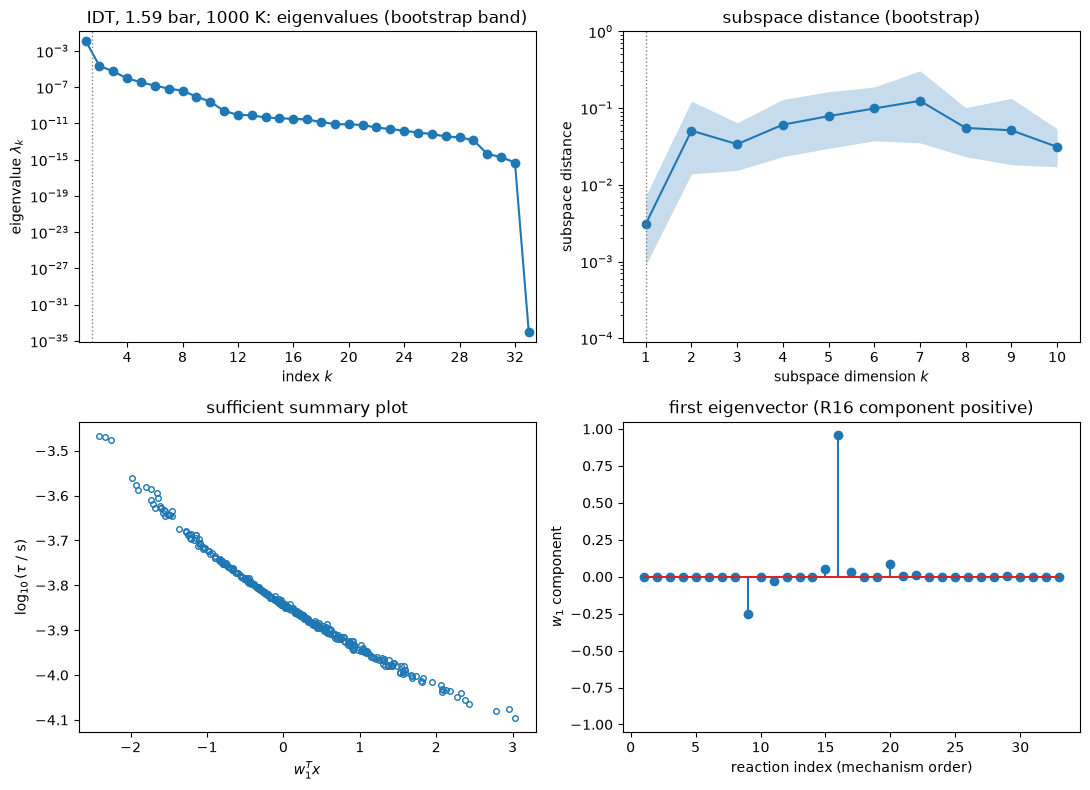

In [6]:
s0 = subs[0]
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ac.plotting.plot_eigenvalues(s0, ax=ax[0, 0], k_max=33)
ax[0, 0].set_title('IDT, 1.59 bar, 1000 K: eigenvalues (bootstrap band)')
ac.plotting.plot_subspace_errors(s0, ax=ax[0, 1], k_max=10)
ax[0, 1].set_title('subspace distance (bootstrap)')
y0 = X @ s0.eigenvectors[:, 0]
ax[1, 0].plot(y0, Q[:, 0], 'o', mfc='none', ms=4)
ax[1, 0].set_xlabel(r'$w_1^T x$'); ax[1, 0].set_ylabel(r'$\log_{10}(\tau$ / s)')
ax[1, 0].set_title('sufficient summary plot')
ax[1, 1].stem(np.arange(1, 34), s0.eigenvectors[:, 0])
ax[1, 1].set_xlabel('reaction index (mechanism order)'); ax[1, 1].set_ylabel(r'$w_1$ component')
ax[1, 1].set_ylim(-1.05, 1.05); ax[1, 1].set_title('first eigenvector (R16 component positive)')
fig.tight_layout()
w = s0.eigenvectors[:, 0]
print(f'lambda_33 = {s0.eigenvalues[-1]:.1e}, lambda_32 = {s0.eigenvalues[-2]:.1e}, lambda_10..lambda_29 between {s0.eigenvalues[28]:.1e} and {s0.eigenvalues[9]:.1e}')
print(f'lambda1 = {s0.eigenvalues[0]:.3e}, lambda2 = {s0.eigenvalues[1]:.3e}, ratio {s0.eigenvalues[0] / s0.eigenvalues[1]:.1f}')
lo, hi = np.percentile(s0.bootstrap_eigenvalues[:, :2], [2.5, 97.5], axis=0)
print(f'bootstrap 95% ranges: lambda1 [{lo[0]:.3e}, {hi[0]:.3e}], lambda2 [{lo[1]:.3e}, {hi[1]:.3e}]')
print('w1 components above 0.05 in magnitude:',
      ', '.join(f'x{j + 1} (Konnov {hd.KONNOV_NO[j]}, {hd.EQUATIONS[j]}) {w[j]:+.3f}' for j in np.argsort(-np.abs(w)) if abs(w[j]) > 0.05))
print(f'log10(tau) range on the 350 samples: [{Q[:, 0].min():.3f}, {Q[:, 0].max():.3f}]; '
      f'w1^T x range [{y0.min():.2f}, {y0.max():.2f}]')
plt.close(fig)
fig

The first eigenvalue, $1.340\times10^{-2}$ (bootstrap 95 % range $[1.271, 1.445]\times10^{-2}$), is 586 times the second, and the bootstrap distance for $n = 1$ is small. The eigenvector is almost all $x_{16}$ (+0.962) with an opposite contribution from $x_9$ (−0.251) and a small one from $x_{20}$ (+0.085), and $\log_{10}\tau$ falls smoothly from −3.466 to −4.095 along $\mathbf w_1^T\mathbf x$ with little scatter. The tail of the spectrum is numerical: $\lambda_{10}$ to $\lambda_{29}$ lie between $10^{-13}$ and $10^{-9}$, $\lambda_{32}$ is of order $10^{-16}$ and $\lambda_{33}$ of order $10^{-34}$ (the argon reaction $x_{10}$ and finite-difference noise in nearly inactive directions); we plot all 33 eigenvalues.

#### Dimension and a surrogate

To check $n = 1$ beyond the eigenvalue gaps, we fit a quadratic polynomial in $y_1 = \mathbf w_1^T\mathbf x$ to each output and give its leave-one-out $R^2$, and the same with two active variables.

In [7]:
r2 = []
for i, s in enumerate(subs):
    sur = ac.fit_surrogate(X=L, f=Q[:, i], subspace=s, kind='poly', degree=2)
    r2.append(sur.loo_r_squared)
sub2 = [ac.with_dimension(s, 2) for s in subs]
r2b = [ac.fit_surrogate(X=L, f=Q[:, i], subspace=s, kind='poly', degree=2).loo_r_squared
       for i, s in enumerate(sub2)]
for i in range(NO):
    print(f'{short[i]:20s} LOO R^2, quadratic in y1: {r2[i]:.4f}; quadratic in (y1, y2): {r2b[i]:.4f}')

IDT 1.57 atm 1000 K  LOO R^2, quadratic in y1: 0.9962; quadratic in (y1, y2): 0.9971
IDT 1 atm 1000 K     LOO R^2, quadratic in y1: 0.9990; quadratic in (y1, y2): 0.9997
IDT 1 atm 1400 K     LOO R^2, quadratic in y1: 0.9987; quadratic in (y1, y2): 0.9995
IDT 1 atm 1800 K     LOO R^2, quadratic in y1: 0.9904; quadratic in (y1, y2): 0.9930
IDT 2 atm 1000 K     LOO R^2, quadratic in y1: 0.9712; quadratic in (y1, y2): 0.9709
IDT 2 atm 1400 K     LOO R^2, quadratic in y1: 0.9989; quadratic in (y1, y2): 0.9997
IDT 2 atm 1800 K     LOO R^2, quadratic in y1: 0.9959; quadratic in (y1, y2): 0.9967
IDT 5 atm 1000 K     LOO R^2, quadratic in y1: 0.9817; quadratic in (y1, y2): 0.9942
IDT 5 atm 1400 K     LOO R^2, quadratic in y1: 0.9990; quadratic in (y1, y2): 0.9998
IDT 5 atm 1800 K     LOO R^2, quadratic in y1: 0.9982; quadratic in (y1, y2): 0.9992
IDT 10 atm 1000 K    LOO R^2, quadratic in y1: 0.9926; quadratic in (y1, y2): 0.9968
IDT 10 atm 1400 K    LOO R^2, quadratic in y1: 0.9988; quadratic 

A quadratic in $y_1$ alone has leave-one-out $R^2$ of at least 0.9712 (ignition at 2 atm and 1000 K, the condition closest to the explosion limit) and above 0.99 for 19 of the 21 outputs; it is 0.9962 at the Fig. 1 condition. A second active variable adds at most 0.0125 (5 atm, 1000 K). With the eigenvalue gaps above, this supports $n = 1$ for every output, as in the paper's Fig. 1.

### The shared subspace

Ji et al. look for one vector $v$ with $u_i^T v = 1$ for every training output $i$, where $u_i$ is that output's first eigenvector (Eq. 8). Then $f_i(\mathbf x) \approx f_i(v\,u_i^T\mathbf x)$ for every $i$, so the single variable $\xi \sim \mathcal N(0,1)$ along $v$ gives each output's distribution, $\mathrm{PDF}[f_i(\mathbf x)] \approx \mathrm{PDF}[f_i(v\,\xi)]$ (Eq. 12). With 20 training outputs and $d = 33$, the minimum-norm solution is $v = A(A^TA)^{-1}\mathbf 1$, $A = [u_2, \dots, u_{21}]$ (Eq. 10). The training outputs are the paper's Sec. 3.2 grid (15 ignition and 5 flame conditions); the Fig. 1 condition, $u_1$, is left out to test the direction on an output it was not built from. The next cell recomputes $u_i$ and $v$ with `h2_konnov_driver.shared_directions` (numpy only), the function `generate_data.py` used to choose the directions of `line_runs.csv`, and checks them against the library's eigenvectors and `directions.csv`.

In [8]:
U, v10, v = hd.shared_directions(F, G)
Wlib = np.array([s.eigenvectors[:, 0] for s in subs])
print(f'library eigenvectors vs h2_konnov_driver.shared_directions: max difference {np.abs(Wlib - U).max():.1e}')
print(f'directions.csv vs recomputed: u {np.abs(DIR[:NO] - U).max():.1e}, v {np.abs(DIR[NO] - v).max():.1e}')
A = U[1:].T
sv = np.linalg.svd(A, compute_uv=False)
print(f'A = [u_2..u_21] (33 x 20): singular values {sv[0]:.3f} ... {sv[-1]:.2e}; condition number {sv[0] / sv[-1]:.2e}')
cosU = U @ U.T
print(f'cosines between the 20 training u_i: {cosU[1:, 1:][np.triu_indices(20, 1)].min():.3f} to '
      f'{cosU[1:, 1:][np.triu_indices(20, 1)].max():.3f}')
for nm, vv in [('Eq. (10) exact', v10), ('truncated SVD', v)]:
    res = A.T @ vv - 1
    print(f'{nm:15s}: |v| = {np.linalg.norm(vv):8.3f}, max |u_i^T v - 1| over training = {np.abs(res).max():.2e}, '
          f'held-out u_1^T v = {U[0] @ vv:.4f}, max |v_j| * 3 = {3 * np.abs(vv).max():.2f}')
P_, s_, Qt_ = np.linalg.svd(A.T, full_matrices=False)
kk = [k for k in range(1, 21) if np.allclose(Qt_[:k].T @ ((P_[:, :k].T @ np.ones(20)) / s_[:k]), v)]
print(f'truncated SVD keeps k = {kk[0]} of 20 singular vectors (rule: smallest k with max |u_i^T v - 1| <= {hd.SHARED_TOL})')
print('largest components of v:', ', '.join(f'x{j + 1} ({hd.EQUATIONS[j]}) {v[j]:+.3f}' for j in np.argsort(-np.abs(v))[:6]))
print('u_i^T v for every output:', np.array2string(U @ v, precision=3))

library eigenvectors vs h2_konnov_driver.shared_directions: max difference 8.9e-15
directions.csv vs recomputed: u 6.7e-16, v 3.4e-15
A = [u_2..u_21] (33 x 20): singular values 3.735 ... 6.63e-05; condition number 5.63e+04
cosines between the 20 training u_i: 0.095 to 0.999
Eq. (10) exact : |v| =   13.786, max |u_i^T v - 1| over training = 2.92e-11, held-out u_1^T v = 0.9916, max |v_j| * 3 = 20.92
truncated SVD  : |v| =    2.505, max |u_i^T v - 1| over training = 2.61e-02, held-out u_1^T v = 0.9948, max |v_j| * 3 = 3.44
truncated SVD keeps k = 8 of 20 singular vectors (rule: smallest k with max |u_i^T v - 1| <= 0.05)
largest components of v: x13 (OH+OH(+M)=H2O2(+M)) +1.146, x16 (H+O2=OH+O) +1.018, x17 (H2+OH=H2O+H) +1.016, x20 (H+HO2=OH+OH) -0.988, x22 (H+HO2=H2+O2) -0.969, x26 (HO2+HO2=H2O2+O2) -0.653
u_i^T v for every output: [0.995 0.989 1.012 0.985 1.005 1.002 1.026 0.994 0.996 1.009 1.026 0.998
 0.993 0.98  0.998 0.983 0.996 1.    1.004 1.004 0.997]


For hydrogen, Eq. (10) is badly conditioned. Most ignition outputs have nearly the same eigenvector (cosines up to 0.999), so $A$ has a condition number of $5.6\times10^4$, and the exact solution has $\lVert v\rVert = 13.8$: at $\xi = 3$ it would move some rate constants by about 21 standard deviations, far outside the input distribution. The paper says only that a rank-deficient $A$ calls for a minimum-norm least-squares solution (p. 149). We regularize by truncating the singular value decomposition of $A^T$: our rule (not the paper's) keeps the fewest singular vectors for which every training output has $|u_i^T v - 1| \le 0.05$. That keeps 8 of 20, gives $\lVert v\rVert = 2.505$ with a largest residual of 0.0261, and puts the largest component at $3|v_j| = 3.44$ standard deviations at $\xi = 3$. The held-out Fig. 1 condition has $u_1^T v = 0.9948$ (0.9916 for the exact solution), so the shared direction also serves an output that was not used to build it. How Approximation III below depends on the tolerance 0.05 is not shown: the model was run along the truncated-SVD $v$ only. Like the paper's Fig. 2b, $v$ mixes the large components of the ignition and flame eigenvectors: $x_{13}$, $x_{16}$, $x_{17}$, $x_{20}$, $x_{22}$ and $x_{26}$ lead.

Fig. 2 analogue (paper p. 152): the first 20 eigenvalues of three ignition delays and one flame speed at 20 atm, and the first eigenvectors of the ignition delay at 20 atm and 1000 K and the flame speed at 20 atm, with the shared direction $v$.

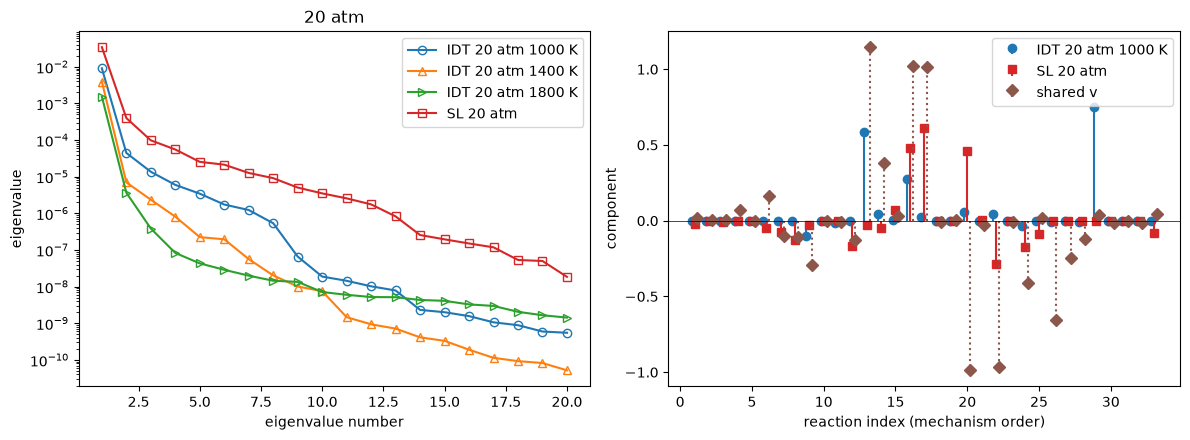

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for i, mk in [(13, 'o-'), (14, '^-'), (15, '>-'), (20, 's-')]:
    ax[0].semilogy(np.arange(1, 21), subs[i].eigenvalues[:20], mk, mfc='none', label=short[i])
ax[0].set_xlabel('eigenvalue number'); ax[0].set_ylabel('eigenvalue'); ax[0].legend(); ax[0].set_title('20 atm')
idx = np.arange(1, 34)
ax[1].stem(idx - 0.2, U[13], linefmt='C0-', markerfmt='C0o', basefmt=' ', label=short[13])
ax[1].stem(idx, U[20], linefmt='C3-', markerfmt='C3s', basefmt=' ', label=short[20])
ax[1].stem(idx + 0.2, v, linefmt='C5:', markerfmt='C5D', basefmt=' ', label='shared v')
ax[1].axhline(0, color='k', lw=0.5)
ax[1].set_xlabel('reaction index (mechanism order)'); ax[1].set_ylabel('component'); ax[1].legend()
fig.tight_layout()
plt.close(fig)
fig

As in the paper's methane case, the first eigenvalue of each output stands well above the rest, and the ignition and flame eigenvectors are led by different reactions: $x_{29}$ and $x_{13}$ for ignition at 20 atm and 1000 K, $x_{17}$, $x_{16}$ and $x_{20}$ for the flame. $v$ has large components on both sets, plus components that serve the other training outputs. Its components are larger than the paper's ($|v_j|$ up to about 1.1 against about 0.7 in Fig. 2b) because $v$ is not a unit vector: $u_i^T v = 1$ fixes its length.

### Approximations II and III, and the output distributions

The paper compares three approximations (p. 151). Approximation II evaluates the model on the output's own active subspace, $f_i(u_i u_i^T\mathbf x)$; Approximation III on the shared one, $f_i(v\,u_i^T\mathbf x)$; both give PDFs from a one-dimensional standard normal (Algorithm 2.2, p. 150). `line_runs.csv` holds the model at $\mathbf x = \xi u_i$ and $\mathbf x = \xi v$ for 49 equally spaced $\xi \in [-4, 4]$ (2058 runs). We interpolate each curve (monotone cubic, `PchipInterpolator`) and (a) compare it with the model at the 350 samples, $y = u_i^T\mathbf x$, as the relative RMS error (divided by the output's standard deviation), and (b) push 100 000 standard normal draws through it (the response surface of Algorithm 2.2) and compare the mean and standard deviation with the 1000 full-model Monte Carlo samples, whose 95 % bootstrap intervals (1000 replicates) are shown. The Monte Carlo inputs are truncated at $\pm3$ and the draws of Algorithm 2.2 are not (as in the paper); the curves cover $|\xi| \le 4$, which drops 6 of the 100 000 draws.

In [10]:
xi = LR[:, 0]
Fv, Fu = LR[:, 1:1 + NO].copy(), LR[:, 1 + NO:].copy()
Fv[:, :NI], Fu[:, :NI] = np.log10(Fv[:, :NI]), np.log10(Fu[:, :NI])
def curve(col):
    return PchipInterpolator(xi, col, extrapolate=False)
rng = np.random.default_rng(SEED)
Xi = rng.standard_normal(100000)
Xi = Xi[np.abs(Xi) <= 4.0]                           # the line runs cover [-4, 4]
print(f'Algorithm 2.2 draws: {len(Xi)} of 100000 standard normals inside [-4, 4]')
def boot_ci(a, stat, B=1000):
    r = np.random.default_rng(SEED)
    vals = np.array([stat(a[r.integers(0, len(a), len(a))]) for _ in range(B)])
    return np.percentile(vals, [2.5, 97.5])
print(f'{"output":20s} {"rel RMS err II":>14s} {"III":>8s} | {"MC mean [95% CI]":>28s} {"II":>8s} {"III":>8s} | '
      f'{"MC sd [95% CI]":>26s} {"II":>8s} {"III":>8s}')
rows = []
for i in range(NO):
    y = X @ U[i]
    gII, gIII = curve(Fu[:, i])(y), curve(Fv[:, i])(y)
    sd = Q[:, i].std()
    eII = np.sqrt(np.mean((gII - Q[:, i])**2)) / sd
    eIII = np.sqrt(np.mean((gIII - Q[:, i])**2)) / sd
    qII, qIII = curve(Fu[:, i])(Xi), curve(Fv[:, i])(Xi)
    mci, sci = boot_ci(Qmc[:, i], np.mean), boot_ci(Qmc[:, i], np.std)
    rows.append((eII, eIII, Qmc[:, i].mean(), qII.mean(), qIII.mean(), Qmc[:, i].std(), qII.std(), qIII.std(), mci, sci))
    print(f'{short[i]:20s} {eII:14.3f} {eIII:8.3f} | {Qmc[:, i].mean():9.4f} [{mci[0]:.4f}, {mci[1]:.4f}] {qII.mean():8.4f} '
          f'{qIII.mean():8.4f} | {Qmc[:, i].std():8.4f} [{sci[0]:.4f}, {sci[1]:.4f}] {qII.std():8.4f} {qIII.std():8.4f}')
rows_ci = rows
rows = np.array([r[:8] for r in rows])
ci_m = np.array([r[8] for r in rows_ci]); ci_s = np.array([r[9] for r in rows_ci])
for nm, sl in [('ignition', slice(0, NI)), ('flame', slice(NI, NO))]:
    R = rows[sl]
    print(f'{nm}: |mean II - MC| up to {np.abs(R[:, 3] - R[:, 2]).max():.4f}, |mean III - MC| up to '
          f'{np.abs(R[:, 4] - R[:, 2]).max():.4f}; mean III - MC from {(R[:, 4] - R[:, 2]).min():+.4f} to '
          f'{(R[:, 4] - R[:, 2]).max():+.4f}; sd II / MC {(R[:, 6] / R[:, 5]).min():.3f} to {(R[:, 6] / R[:, 5]).max():.3f}, '
          f'sd III / MC {(R[:, 7] / R[:, 5]).min():.3f} to {(R[:, 7] / R[:, 5]).max():.3f}')
    print(f'   means outside the MC 95% interval: II {np.sum((R[:, 3] < ci_m[sl, 0]) | (R[:, 3] > ci_m[sl, 1]))}, '
          f'III {np.sum((R[:, 4] < ci_m[sl, 0]) | (R[:, 4] > ci_m[sl, 1]))} of {len(R)}; sds outside: II '
          f'{np.sum((R[:, 6] < ci_s[sl, 0]) | (R[:, 6] > ci_s[sl, 1]))}, III {np.sum((R[:, 7] < ci_s[sl, 0]) | (R[:, 7] > ci_s[sl, 1]))}')
    print(f'   error III - error II from {(R[:, 1] - R[:, 0]).min():+.3f} to {(R[:, 1] - R[:, 0]).max():+.3f}')
print('(errors: RMS of curve - model over the 350 samples, divided by the sd of the output; '
      'log10 tau in log10(s), S_L in m/s)')

Algorithm 2.2 draws: 99994 of 100000 standard normals inside [-4, 4]
output               rel RMS err II      III |             MC mean [95% CI]       II      III |             MC sd [95% CI]       II      III
IDT 1.57 atm 1000 K           0.047    0.049 |   -3.8286 [-3.8353, -3.8217]  -3.8318  -3.8321 |   0.1130 [0.1059, 0.1213]   0.1188   0.1177
IDT 1 atm 1000 K              0.036    0.039 |   -3.7753 [-3.7792, -3.7712]  -3.7779  -3.7780 |   0.0677 [0.0648, 0.0706]   0.0709   0.0700
IDT 1 atm 1400 K              0.036    0.038 |   -4.7393 [-4.7415, -4.7373]  -4.7402  -4.7402 |   0.0363 [0.0348, 0.0377]   0.0381   0.0385
IDT 1 atm 1800 K              0.112    0.120 |   -5.0561 [-5.0578, -5.0545]  -5.0550  -5.0547 |   0.0281 [0.0269, 0.0293]   0.0293   0.0287


IDT 2 atm 1000 K              0.063    0.066 |   -3.7340 [-3.7478, -3.7198]  -3.7357  -3.7361 |   0.2292 [0.2133, 0.2447]   0.2465   0.2453
IDT 2 atm 1400 K              0.035    0.035 |   -5.0607 [-5.0630, -5.0585]  -5.0620  -5.0620 |   0.0383 [0.0367, 0.0397]   0.0401   0.0402
IDT 2 atm 1800 K              0.068    0.071 |   -5.4475 [-5.4493, -5.4457]  -5.4473  -5.4473 |   0.0306 [0.0293, 0.0318]   0.0320   0.0327
IDT 5 atm 1000 K              0.136    0.145 |   -2.4357 [-2.4431, -2.4278]  -2.4390  -2.4355 |   0.1243 [0.1182, 0.1301]   0.1263   0.1282
IDT 5 atm 1400 K              0.037    0.037 |   -5.4642 [-5.4667, -5.4618]  -5.4659  -5.4659 |   0.0413 [0.0396, 0.0429]   0.0433   0.0431


IDT 5 atm 1800 K              0.043    0.044 |   -5.9149 [-5.9170, -5.9130]  -5.9155  -5.9156 |   0.0340 [0.0326, 0.0354]   0.0356   0.0359
IDT 10 atm 1000 K             0.087    0.127 |   -2.3668 [-2.3724, -2.3609]  -2.3709  -2.3657 |   0.0945 [0.0901, 0.0986]   0.0964   0.0982
IDT 10 atm 1400 K             0.042    0.042 |   -5.7448 [-5.7477, -5.7422]  -5.7471  -5.7470 |   0.0463 [0.0444, 0.0481]   0.0485   0.0482
IDT 10 atm 1800 K             0.039    0.041 |   -6.2457 [-6.2479, -6.2437]  -6.2468  -6.2469 |   0.0359 [0.0344, 0.0373]   0.0375   0.0372
IDT 20 atm 1000 K             0.072    0.101 |   -2.4325 [-2.4378, -2.4267]  -2.4369  -2.4329 |   0.0940 [0.0895, 0.0980]   0.0963   0.0930


IDT 20 atm 1400 K             0.052    0.054 |   -5.9739 [-5.9776, -5.9704]  -5.9770  -5.9772 |   0.0606 [0.0580, 0.0632]   0.0634   0.0628
IDT 20 atm 1800 K             0.041    0.046 |   -6.5630 [-6.5653, -6.5609]  -6.5645  -6.5645 |   0.0376 [0.0361, 0.0391]   0.0393   0.0385
SL 1 atm                      0.151    0.141 |    2.3114 [2.3015, 2.3213]   2.3303   2.3280 |   0.1608 [0.1531, 0.1681]   0.1617   0.1607
SL 2 atm                      0.158    0.147 |    2.2336 [2.2223, 2.2447]   2.2562   2.2535 |   0.1842 [0.1755, 0.1924]   0.1853   0.1847
SL 5 atm                      0.162    0.151 |    1.9437 [1.9311, 1.9558]   1.9697   1.9663 |   0.2042 [0.1945, 0.2131]   0.2057   0.2055


SL 10 atm                     0.165    0.154 |    1.5890 [1.5765, 1.6012]   1.6162   1.6125 |   0.2049 [0.1949, 0.2138]   0.2070   0.2065
SL 20 atm                     0.160    0.147 |    1.1602 [1.1490, 1.1712]   1.1845   1.1808 |   0.1849 [0.1763, 0.1929]   0.1878   0.1855
ignition: |mean II - MC| up to 0.0044, |mean III - MC| up to 0.0035; mean III - MC from -0.0035 to +0.0014; sd II / MC 1.016 to 1.075, sd III / MC 0.990 to 1.072
   means outside the MC 95% interval: II 0, III 0 of 16; sds outside: II 11, III 7
   error III - error II from -0.000 to +0.040
flame: |mean II - MC| up to 0.0272, |mean III - MC| up to 0.0236; mean III - MC from +0.0165 to +0.0236; sd II / MC 1.005 to 1.016, sd III / MC 0.999 to 1.008
   means outside the MC 95% interval: II 5, III 5 of 5; sds outside: II 0, III 0
   error III - error II from -0.013 to -0.010
(errors: RMS of curve - model over the 350 samples, divided by the sd of the output; log10 tau in log10(s), S_L in m/s)


In [11]:
# curvature in the inactive directions: fit grad(x) ~ b + H x by least squares (350 x 34) and predict
# E[f(x)] - f(u u^T x) ~ 1/2 tr(H (I - u u^T)), the gap that evaluating on the line leaves (second order)
A1 = np.column_stack([np.ones(len(X)), X])
pred = np.zeros(NO)
for i in range(NO):
    Hi = np.linalg.lstsq(A1, dQ[:, i, :] * hd.SIGMA, rcond=None)[0][1:]
    Hi = 0.5 * (Hi + Hi.T)
    pred[i] = 0.5 * np.trace(Hi @ (np.eye(hd.M_IN) - np.outer(U[i], U[i])))
for i in [0] + list(range(NI, NO)):
    print(f'{short[i]:20s} MC mean - II mean: predicted {pred[i]:+.4f}, observed {rows[i, 2] - rows[i, 3]:+.4f}'
          f' ({"log10 s" if i < NI else "m/s"})')
print(f'ignition, all 16: predicted |MC - II| up to {np.abs(pred[:NI]).max():.4f} log10 s')

IDT 1.57 atm 1000 K  MC mean - II mean: predicted +0.0022, observed +0.0032 (log10 s)
SL 1 atm             MC mean - II mean: predicted -0.0201, observed -0.0189 (m/s)
SL 2 atm             MC mean - II mean: predicted -0.0239, observed -0.0226 (m/s)
SL 5 atm             MC mean - II mean: predicted -0.0270, observed -0.0259 (m/s)
SL 10 atm            MC mean - II mean: predicted -0.0270, observed -0.0272 (m/s)
SL 20 atm            MC mean - II mean: predicted -0.0235, observed -0.0243 (m/s)
ignition, all 16: predicted |MC - II| up to 0.0033 log10 s


The shared direction costs almost nothing. The relative RMS error of Approximation III is 0.035–0.154 against 0.035–0.165 for Approximation II: for the ignition delays it is up to 0.040 larger, most at 10 and 20 atm and 1000 K (0.127 and 0.101 against 0.087 and 0.072), where ignition runs through H$_2$O$_2$; for every flame speed it is 0.010–0.013 smaller. For the 16 ignition delays, the means of both approximations fall within 0.0044 (in $\log_{10}$ s) of the Monte Carlo mean and inside its 95 % interval, and the standard deviations are up to 7.5 % larger (II: 1.016–1.075 times, III: 0.990–1.072 times the Monte Carlo value; outside its interval for 11 outputs with II and 7 with III). For the flame speeds the standard deviations agree within 1.6 %, but both approximations put the mean above the Monte Carlo mean (III: by 0.0165–0.0236 m/s), outside its 95 % interval at all five pressures. The offset is curvature, not a defect of the data. Approximations II and III evaluate the model on the line (inactive variables at zero) instead of averaging over the inactive variables, and for a curved response that misses $\tfrac12\operatorname{tr}(H(I-u_iu_i^T))$ to second order, where $H$ is the Hessian (here a least-squares fit of the stored gradients on $\mathbf x$). The cell above predicts a Monte Carlo mean below the Approximation II mean by 0.0201, 0.0239, 0.0270, 0.0270 and 0.0235 m/s at 1, 2, 5, 10 and 20 atm; the observed differences are 0.0189, 0.0226, 0.0259, 0.0272 and 0.0243 m/s. For ignition the predicted gap is at most 0.0033 in $\log_{10}$ s (+0.0022 at the Fig. 1 condition, observed +0.0032), inside the Monte Carlo intervals. The paper's Approximation I (the conditional mean) would remove this second-order gap at the cost of runs along the inactive directions.

Fig. 3b and Fig. 4 analogues (paper p. 153): summary plots with Approximations II and III (top) and histograms of the output from the 1000 Monte Carlo runs and from Algorithm 2.2 (bottom), for the held-out Fig. 1 condition, ignition at 20 atm and 1000 K, and the flame speed at 20 atm.

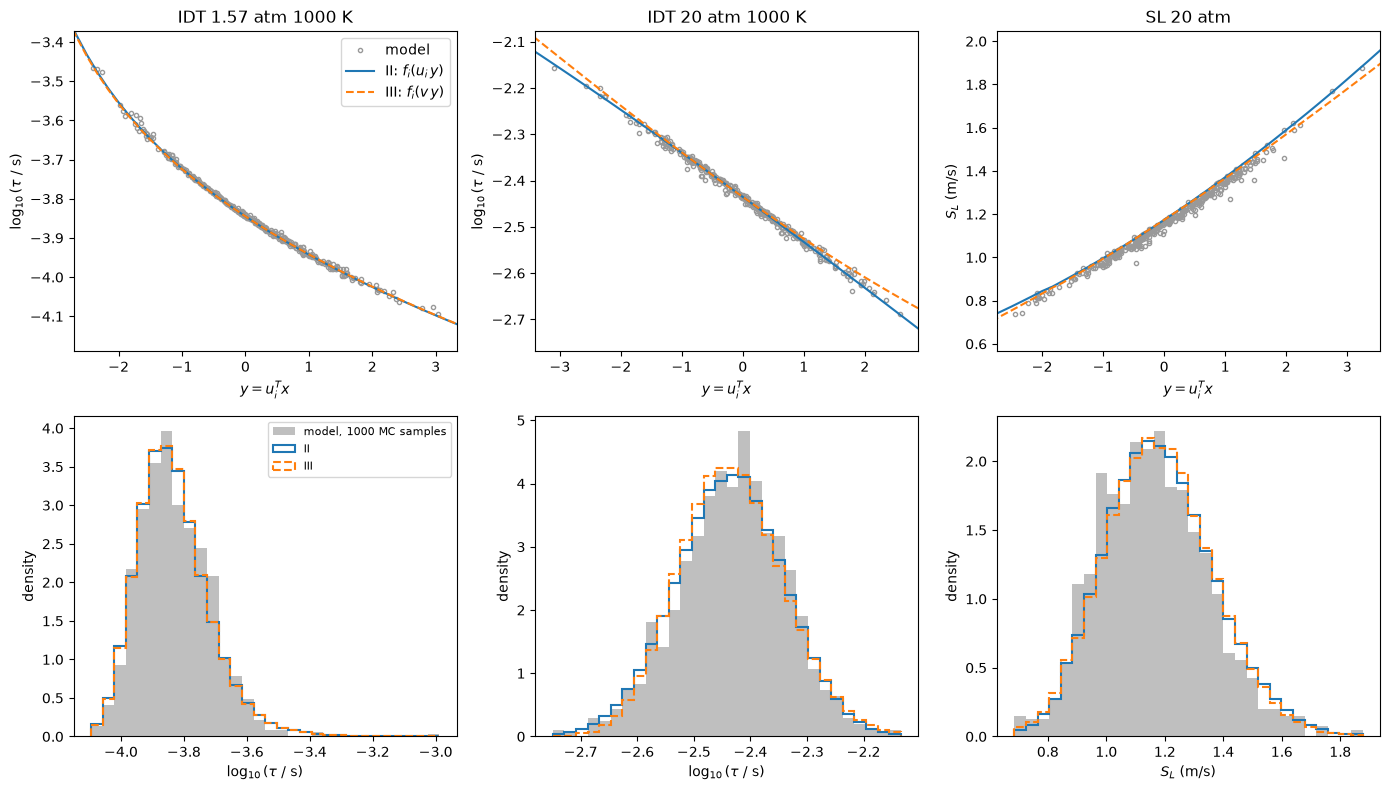

In [12]:
show = [0, 13, 20]
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for c, i in enumerate(show):
    y = X @ U[i]
    ax[0, c].plot(y, Q[:, i], 'o', mfc='none', ms=3, color='0.6', label='model')
    ax[0, c].plot(xi, Fu[:, i], '-', label=r'II: $f_i(u_i\,y)$')
    ax[0, c].plot(xi, Fv[:, i], '--', label=r'III: $f_i(v\,y)$')
    ax[0, c].set_xlim(y.min() - 0.3, y.max() + 0.3)
    lo_, hi_ = Q[:, i].min(), Q[:, i].max()
    ax[0, c].set_ylim(lo_ - 0.15 * (hi_ - lo_), hi_ + 0.15 * (hi_ - lo_))
    ax[0, c].set_xlabel(r'$y = u_i^T x$'); ax[0, c].set_title(short[i])
    ax[0, c].set_ylabel(r'$\log_{10}(\tau$ / s)' if i < NI else r'$S_L$ (m/s)')
    bins = np.linspace(min(Qmc[:, i].min(), lo_), max(Qmc[:, i].max(), hi_), 31)
    ax[1, c].hist(Qmc[:, i], bins=bins, density=True, color='0.75', label='model, 1000 MC samples')
    ax[1, c].hist(curve(Fu[:, i])(Xi), bins=bins, density=True, histtype='step', lw=1.5, label='II')
    ax[1, c].hist(curve(Fv[:, i])(Xi), bins=bins, density=True, histtype='step', lw=1.5, ls='--', label='III')
    ax[1, c].set_xlabel(ax[0, c].get_ylabel()); ax[1, c].set_ylabel('density')
ax[0, 0].legend(); ax[1, 0].legend(fontsize=8)
fig.tight_layout()
plt.close(fig)
fig

The curves follow the samples closely for both ignition delays, including the held-out condition, and the three histograms nearly coincide. For the flame speed the samples scatter around the curves, and the curves run slightly above the bulk of them, which is the mean offset found above.

### Comparison with the paper

| quantity | paper (page) | this notebook |
|---|---|---|
| mechanism, inputs | Konnov (2008), 33 reactions, UFs from Konnov (Table 1, p. 150) | same; UFs read from Konnov Table 1 |
| input distribution | log-normal, sd $\frac13\ln$UF, truncated at $\pm3$ sd (Eqs. 1–2, p. 148) | same |
| samples | $M = \alpha\beta\log d$, $\alpha=\beta=10$ (pp. 148, 151) | 350 |
| bootstrap replicates | 100 (p. 151) | 200 |
| gradients | FD, $\delta = 10^{-3}$ (IDT); adjoint (SL) (p. 150) | FD, $\delta = 10^{-3}$, for both |
| Fig. 1: $\lambda_1$ (1.59 bar, 1000 K) | about $1.5\times10^{-2}$ (read from Fig. 1a, p. 151) | $1.340\times10^{-2}$ |
| Fig. 1: $\lambda_1/\lambda_2$ | "two orders of magnitude" (p. 151); about $10^2$ in Fig. 1a ($\lambda_2$ about $1.5\times10^{-4}$) | 586 |
| Fig. 1: $\lambda_k$, $k \ge 4$ | a floor near $10^{-5}$ (Fig. 1a) | below $10^{-6}$ |
| Fig. 1c: $\mathbf w_1$ | R16 about +0.92, R9 about −0.38 (read from the figure) | $x_{16}$ +0.962, $x_9$ −0.251 |
| Fig. 1b: range of $\log_{10}\tau$ | about −4.1 to −3.0 | −4.095 to −3.466 |
| shared subspace, H$_2$ | not reported (methane only: Figs. 2–4) | 20 training outputs, $\lVert v\rVert$ = 2.505 (truncated SVD), held-out $u_1^Tv$ = 0.9948 |
| conditioning of Eq. (10) | not reported | condition number $5.6\times10^4$, exact $\lVert v\rVert$ = 13.8 |
| Approximations II/III vs model | close for methane IDT (Figs. 3b, 4) | relative RMS 0.035–0.165 (II), 0.035–0.154 (III); flame-speed means 0.017–0.024 m/s high (III), the second-order curvature gap (predicted 0.020–0.027 m/s for II) |

The single-output picture of Fig. 1 is reproduced: one dominant direction led by R16 with an opposite R9 contribution. Our gap is larger and our $x_9$ weight smaller than the paper's. Possible reasons, none checkable from the paper: its ignition-delay definition and mixture, its finite-difference noise (the floor near $10^{-5}$ in Fig. 1a, which the paper itself attributes to $\delta$ at another condition, p. 152), and the reading of a small figure. The two samples near $\log_{10}\tau = -3$ in Fig. 1b have no counterpart in our 350 samples. The shared-subspace comparison has no hydrogen counterpart in the paper; for hydrogen it works, but only after regularizing Eq. (10).

### References


1. W. Ji, J. Wang, O. Zahm, Y. M. Marzouk, B. Yang, Z. Ren, C. K. Law, Shared low-dimensional subspaces for propagating kinetic uncertainty to multiple outputs, *Combustion and Flame* 190 (2018) 146–157. https://doi.org/10.1016/j.combustflame.2017.11.021
2. A. A. Konnov, Remaining uncertainties in the kinetic mechanism of hydrogen combustion, *Combustion and Flame* 152 (2008) 507–528. https://doi.org/10.1016/j.combustflame.2007.10.024
3. P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. https://doi.org/10.1137/1.9781611973860
4. D. G. Goodwin, H. K. Moffat, I. Schoegl, R. L. Speth, B. W. Weber, Cantera: an object-oriented software toolkit for chemical kinetics, thermodynamics, and transport processes, version 3.2.0. https://www.cantera.org

### Acknowledgments

The paper's work was supported by the National Natural Science Foundation of China (Nos. 91441202, 91541113) and by the DARPA EQUiPS program (p. 156).

In [13]:
print(f'notebook run time {time.perf_counter() - t_start:.1f} s')

notebook run time 11.9 s
